# Data Visualisation: Charts for the Capstone Questions

Part of my IBM Data Analyst Capstone project. This notebook brings together the charts I built for the capstone's business questions using the Stack Overflow developer survey: which languages and databases are in demand, who the respondents are, and how compensation varies. It uses bar, pie, bubble, stacked bar, box, scatter and line charts.

Notes on reading the charts:
- Many survey questions allow several answers, so I split them into one row per answer. Counts are mentions, not respondents.
- Pie slices show each item's share of the top five only.
- Age is recorded as ranges and is converted to approximate midpoints where a number is needed.
- Compensation charts use `ConvertedCompYearly` (USD) and leave out respondents who did not report pay. Some also cap extreme values, as noted in each title.

The SQL-based charts are in the previous notebook.

## Setup

In [1]:
!wget -q -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('survey-data.csv')
df.shape

In [3]:
# --- Numeric versions of text columns ---
age_map = {
    'Under 18 years old': 16, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70
}
df['AgeNum'] = df['Age'].map(age_map)
age_order = list(age_map.keys())
df['Age_numeric'] = df['Age'].map(age_map)
df['JobSatNum'] = pd.to_numeric(df['JobSat'], errors='coerce')

short_names = {
    'United States of America': 'USA',
    'United Kingdom of Great Britain and Northern Ireland': 'UK',
    'Russian Federation': 'Russia', 'Iran, Islamic Republic of...': 'Iran'
}

# --- Helper 1: items (rows) vs groups (columns), bubble size = frequency ---
def bubble_matrix(data, group_col, item_col, group_order=None, top_items=10,
                  top_groups=None, title='', xlabel='', ylabel=''):
    d = data[[group_col, item_col]].dropna()
    if top_groups:
        d = d[d[group_col].isin(d[group_col].value_counts().head(top_groups).index)]
    d = d.assign(item=d[item_col].str.split(';')).explode('item')
    d['item'] = d['item'].str.strip()
    d = d[d['item'].isin(d['item'].value_counts().head(top_items).index)]

    counts = d.groupby([group_col, 'item']).size().unstack(fill_value=0)
    if group_order is not None:
        counts = counts.reindex([g for g in group_order if g in counts.index])
    counts = counts[counts.sum().sort_values().index]      # rarest item first

    xs, ys = np.meshgrid(range(len(counts.index)), range(len(counts.columns)))
    sizes = counts.T.values / counts.values.max() * 1200

    plt.figure(figsize=(12, 7))
    plt.scatter(xs.ravel(), ys.ravel(), s=sizes.ravel(), alpha=0.5,
                color='tab:blue', edgecolors='k', linewidths=0.4)
    plt.xticks(range(len(counts.index)),
               [short_names.get(g, g) for g in counts.index], rotation=30, ha='right')
    plt.yticks(range(len(counts.columns)), counts.columns)
    plt.margins(0.12)
    plt.grid(alpha=0.3)
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title)
    plt.tight_layout(); plt.show()

# --- Helper 2: item vs average job satisfaction, bubble size = respondents ---
def bubble_vs_satisfaction(data, item_col, top_n=10, title='', ylabel=''):
    d = data[[item_col, 'JobSatNum']].dropna()
    d = d.assign(item=d[item_col].str.split(';')).explode('item')
    d['item'] = d['item'].str.strip()
    d = d[d['item'].isin(d['item'].value_counts().head(top_n).index)]
    stats = d.groupby('item').agg(n=('item', 'size'),
                                  avg_sat=('JobSatNum', 'mean')).sort_values('avg_sat')

    plt.figure(figsize=(10, 6))
    plt.scatter(stats['avg_sat'], range(len(stats)),
                s=stats['n'] / stats['n'].max() * 1500,
                alpha=0.5, color='tab:green', edgecolors='k')
    plt.yticks(range(len(stats)), stats.index)
    plt.margins(0.15)
    plt.grid(alpha=0.3)
    plt.xlabel('Average Job Satisfaction (JobSat)')
    plt.ylabel(ylabel); plt.title(title)
    plt.tight_layout(); plt.show()

## 1. Which programming languages are in demand?
The five languages respondents most want to work with.

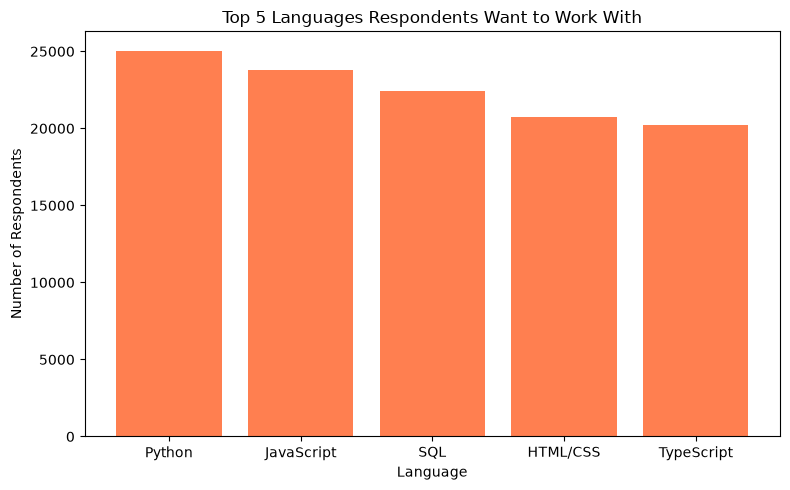

In [4]:
langs = (df['LanguageWantToWorkWith'].dropna()
         .str.split(';')
         .explode()
         .str.strip())
top5_langs = langs.value_counts().head(5)

plt.figure(figsize=(8, 5))
plt.bar(top5_langs.index, top5_langs.values, color='coral')
plt.title('Top 5 Languages Respondents Want to Work With')
plt.xlabel('Language')
plt.ylabel('Number of Respondents')
plt.tight_layout()
plt.show()

Share of the five languages respondents have worked with the most. JavaScript leads with 37,492 mentions, followed by HTML/CSS (31,816), Python (30,719), SQL (30,682) and TypeScript (23,150).

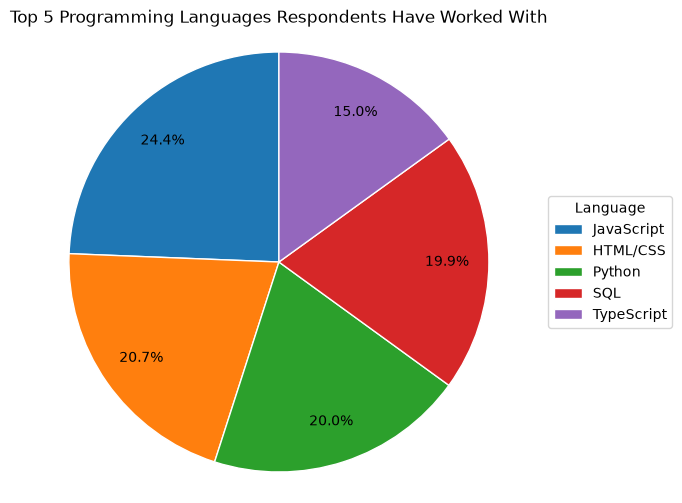

LanguageHaveWorkedWith
JavaScript    37492
HTML/CSS      31816
Python        30719
SQL           30682
TypeScript    23150
Name: count, dtype: int64

In [5]:
items = df['LanguageHaveWorkedWith'].dropna().str.split(';').explode().str.strip()
top5 = items.value_counts().head(5)

plt.figure(figsize=(10, 6))
plt.pie(top5.values, autopct='%1.1f%%', startangle=90,
        pctdistance=0.8, wedgeprops={'edgecolor': 'white'})
plt.legend(top5.index, title='Language', loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Top 5 Programming Languages Respondents Have Worked With')
plt.axis('equal')
plt.subplots_adjust(right=0.65)
plt.show()

print(top5)

Languages used by age group. Bigger bubbles mean more respondents.

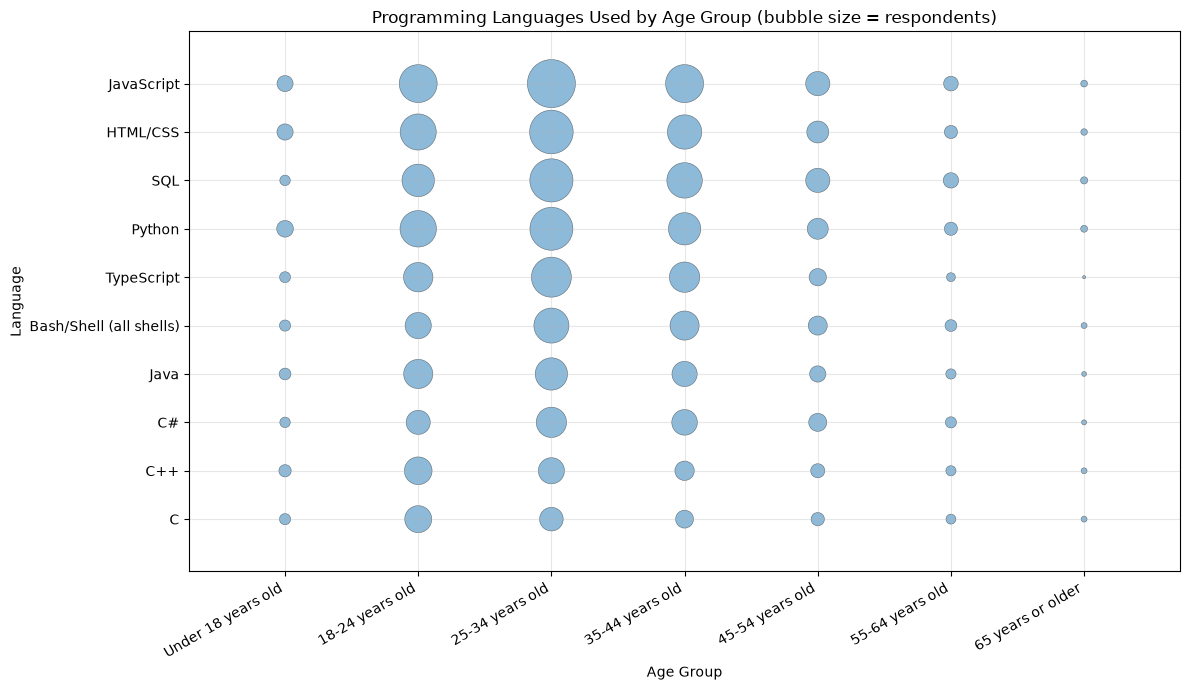

In [6]:
bubble_matrix(df, group_col='Age', item_col='LanguageHaveWorkedWith',
              group_order=sorted(age_map, key=age_map.get), top_items=10,
              title='Programming Languages Used by Age Group (bubble size = respondents)',
              xlabel='Age Group', ylabel='Language')

## 2. Which databases are in demand?
The ten databases respondents have worked with the most.

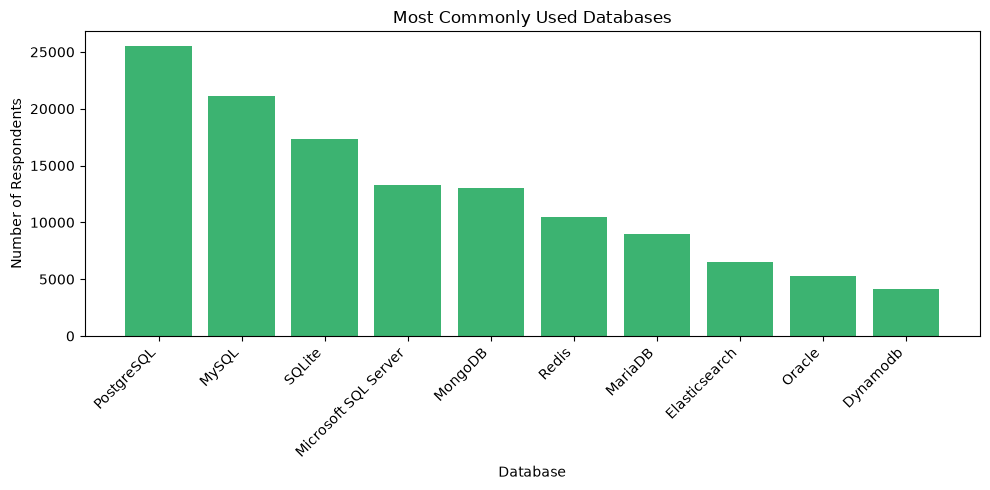

In [7]:
dbs = (df['DatabaseHaveWorkedWith'].dropna()
       .str.split(';')
       .explode()
       .str.strip())
top_dbs = dbs.value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_dbs.index, top_dbs.values, color='mediumseagreen')
plt.title('Most Commonly Used Databases')
plt.xlabel('Database')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Databases respondents want to learn, as a share within each age group.

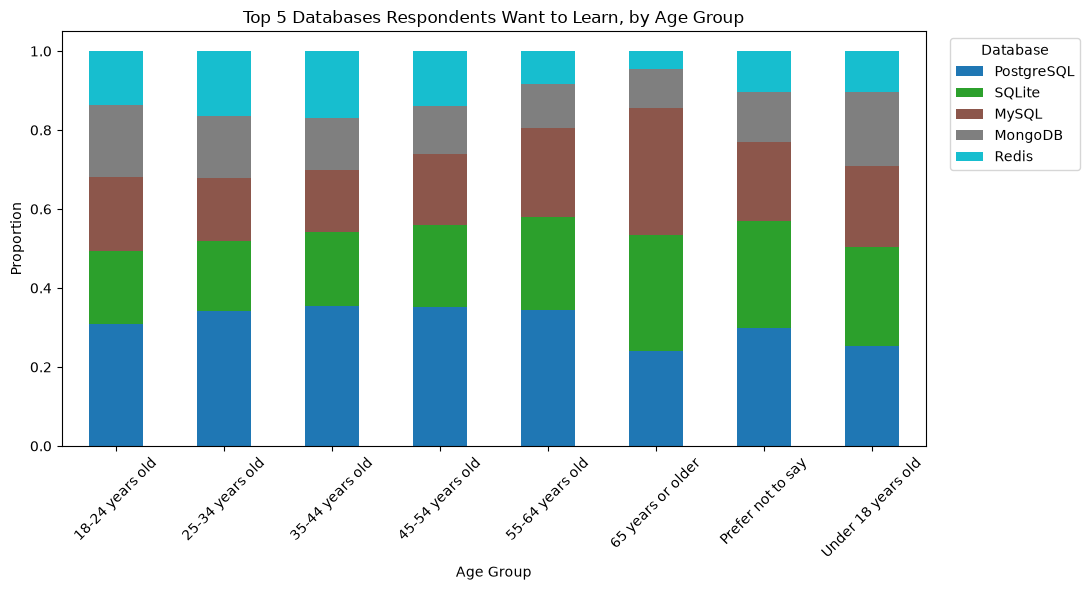

In [8]:
db = (df.assign(DB=df['DatabaseWantToWorkWith'].str.split(';'))
        .explode('DB', ignore_index=True)
        .dropna(subset=['DB']))

counts = pd.crosstab(db['Age'], db['DB'])
top5 = counts.sum().nlargest(5).index          # 5 most wanted databases overall
props = counts[top5].div(counts[top5].sum(axis=1), axis=0)   # proportion per age group

props.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='tab10')
plt.title('Top 5 Databases Respondents Want to Learn, by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Proportion')
plt.xticks(rotation=45)
plt.legend(title='Database', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Preferred databases against average job satisfaction. Bubble size shows the number of respondents. Only respondents who answered the job satisfaction question are included.

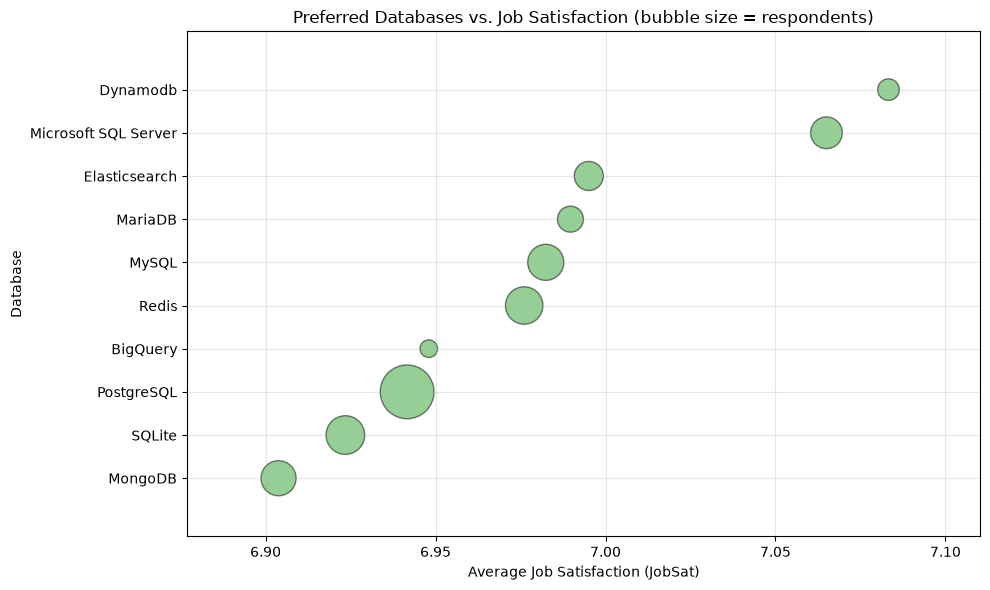

In [9]:
bubble_vs_satisfaction(df, 'DatabaseWantToWorkWith', top_n=10,
                       title='Preferred Databases vs. Job Satisfaction (bubble size = respondents)',
                       ylabel='Database')

## 3. Who are the respondents?
The fifteen countries with the most respondents.

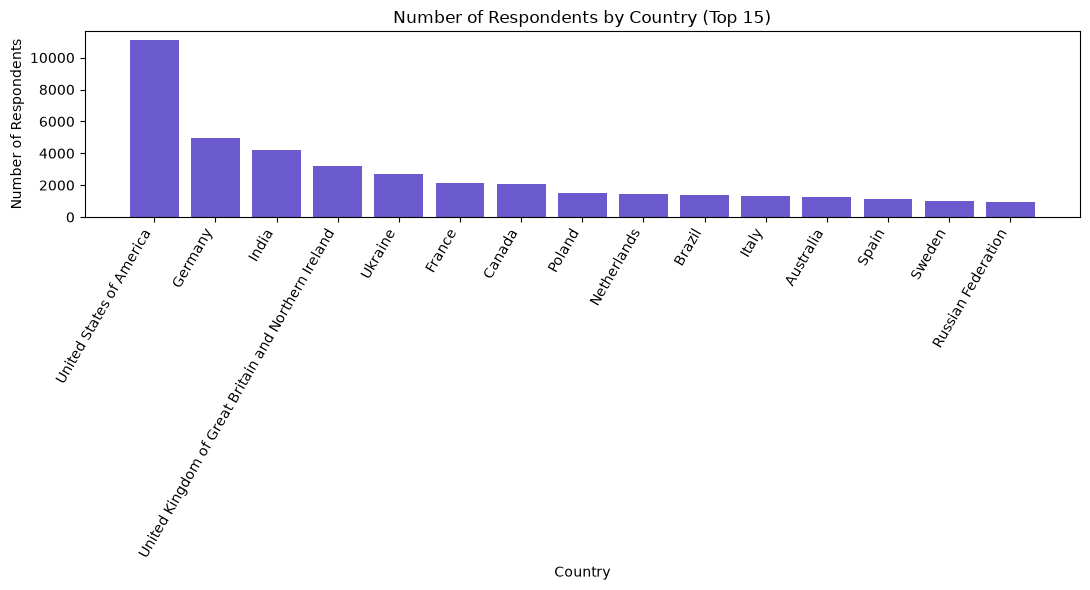

In [10]:
country_counts = df['Country'].value_counts().head(15)

plt.figure(figsize=(11, 6))
plt.bar(country_counts.index, country_counts.values, color='slateblue')
plt.title('Number of Respondents by Country (Top 15)')
plt.xlabel('Country')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

The five most common developer roles. Full-stack developers are the largest group (18,260), followed by back-end developers (9,928) and students (5,102).

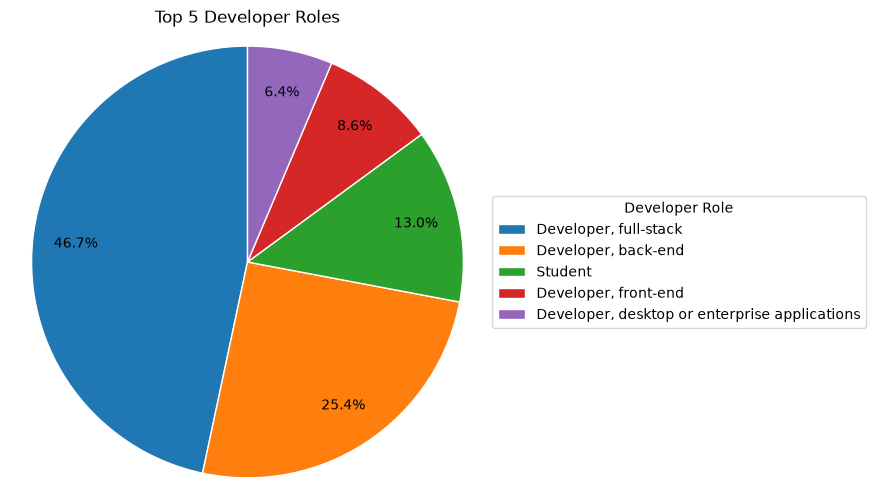

DevType
Developer, full-stack                            18260
Developer, back-end                               9928
Student                                           5102
Developer, front-end                              3349
Developer, desktop or enterprise applications     2493
Name: count, dtype: int64

In [11]:
items = df['DevType'].dropna().str.split(';').explode().str.strip()
top5 = items.value_counts().head(5)

plt.figure(figsize=(10, 6))
plt.pie(top5.values, autopct='%1.1f%%', startangle=90,
        pctdistance=0.8, wedgeprops={'edgecolor': 'white'})
plt.legend(top5.index, title='Developer Role', loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.title('Top 5 Developer Roles')
plt.axis('equal')
plt.subplots_adjust(right=0.60)
plt.show()

print(top5)

Admired programming languages by age group, as a share within each group.

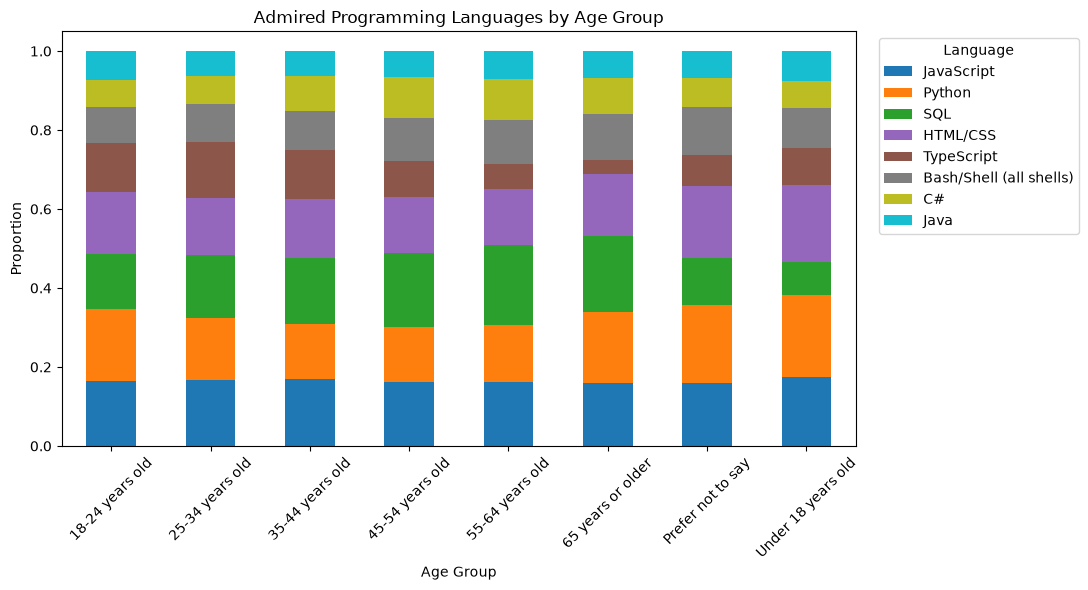

In [12]:
lang = (df.assign(Lang=df['LanguageAdmired'].str.split(';'))
          .explode('Lang', ignore_index=True)
          .dropna(subset=['Lang']))

counts = pd.crosstab(lang['Age'], lang['Lang'])
top_langs = counts.sum().nlargest(8).index
props = counts[top_langs].div(counts[top_langs].sum(axis=1), axis=0)

props.plot(kind='bar', stacked=True, figsize=(11, 6), colormap='tab10')
plt.title('Admired Programming Languages by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Proportion')
plt.xticks(rotation=45)
plt.legend(title='Language', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4. How does compensation vary?
Yearly compensation for the five most common developer types (top 5% trimmed).

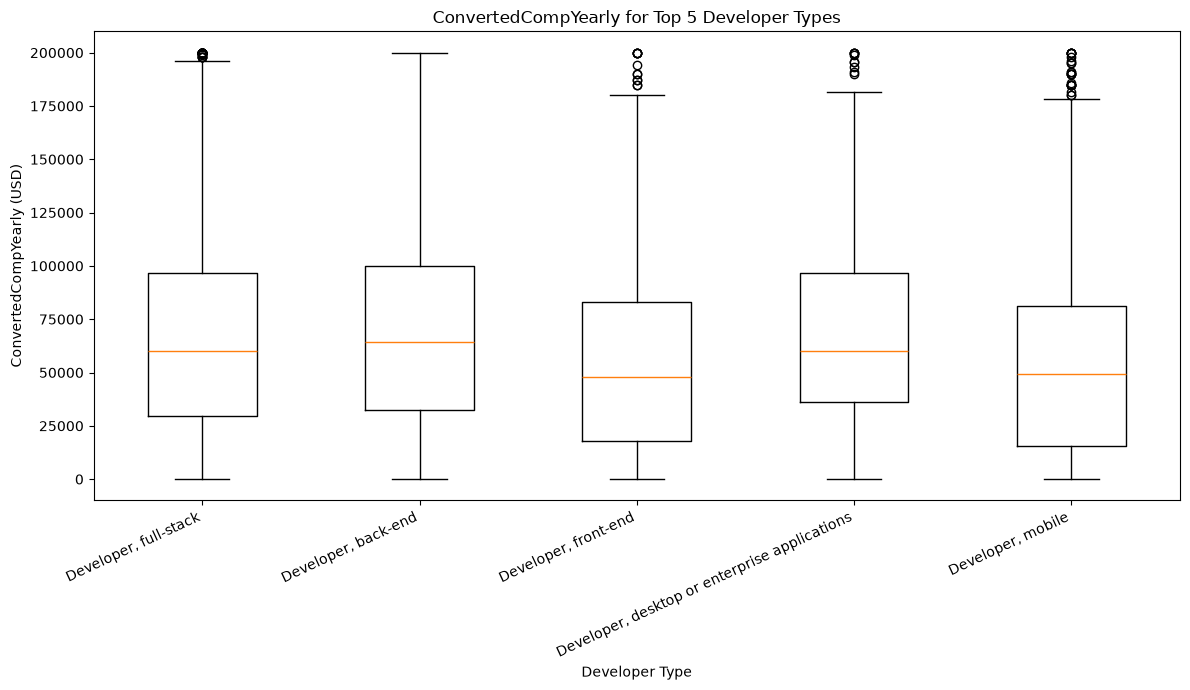

In [13]:
# Top 5 developer types (DevType holds several roles per respondent)
dev = df[['DevType', 'ConvertedCompYearly']].dropna()
dev = dev.assign(DevType=dev['DevType'].str.split(';')).explode('DevType')
dev['DevType'] = dev['DevType'].str.strip()

top5 = dev['DevType'].value_counts().head(5).index.tolist()
dev = dev[dev['DevType'].isin(top5)]

# Trim the top 5% so a few extreme salaries don't flatten the boxes
upper = dev['ConvertedCompYearly'].quantile(0.95)
dev = dev[dev['ConvertedCompYearly'] <= upper]

data = [dev[dev['DevType'] == d]['ConvertedCompYearly'] for d in top5]

plt.figure(figsize=(12, 7))
plt.boxplot(data, tick_labels=top5)
plt.title('ConvertedCompYearly for Top 5 Developer Types')
plt.xlabel('Developer Type')
plt.ylabel('ConvertedCompYearly (USD)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

Age against yearly compensation, for respondents earning up to 300,000 USD.

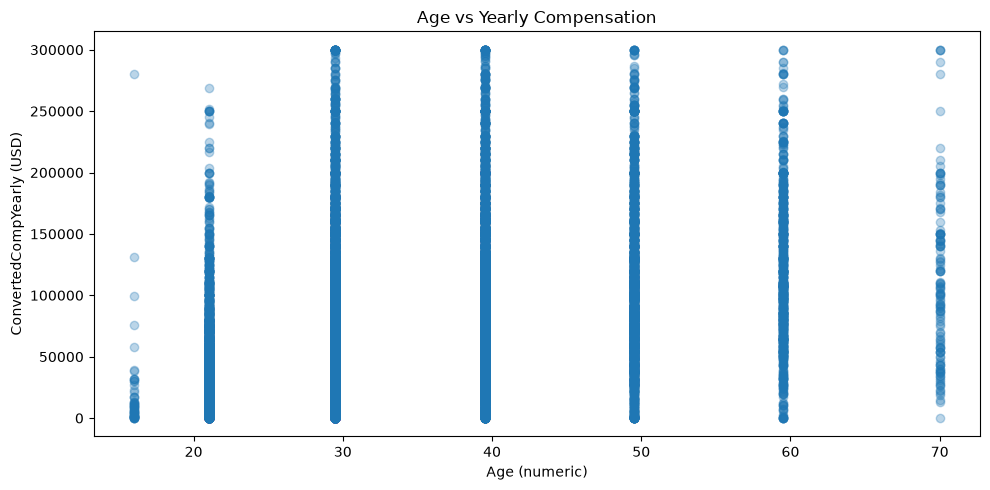

In [14]:
d = df.dropna(subset=['Age_numeric', 'ConvertedCompYearly'])
d = d[d['ConvertedCompYearly'] <= 300000]

plt.figure(figsize=(10, 5))
plt.scatter(d['Age_numeric'], d['ConvertedCompYearly'], alpha=0.3)
plt.title('Age vs Yearly Compensation')
plt.xlabel('Age (numeric)')
plt.ylabel('ConvertedCompYearly (USD)')
plt.tight_layout()
plt.show()

Median yearly compensation by age group.

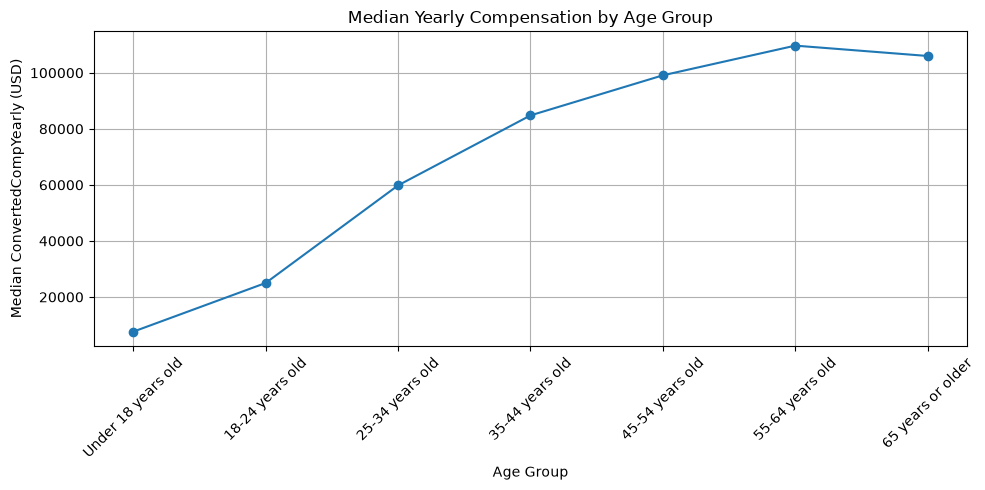

In [15]:
age_order = ['Under 18 years old', '18-24 years old', '25-34 years old',
             '35-44 years old', '45-54 years old', '55-64 years old',
             '65 years or older']

median_comp_age = (df[df['Age'].isin(age_order)]
                   .groupby('Age')['ConvertedCompYearly']
                   .median()
                   .reindex(age_order))

plt.figure(figsize=(10, 5))
plt.plot(median_comp_age.index, median_comp_age.values, marker='o')
plt.title('Median Yearly Compensation by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Median ConvertedCompYearly (USD)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Median yearly compensation by years of work experience.

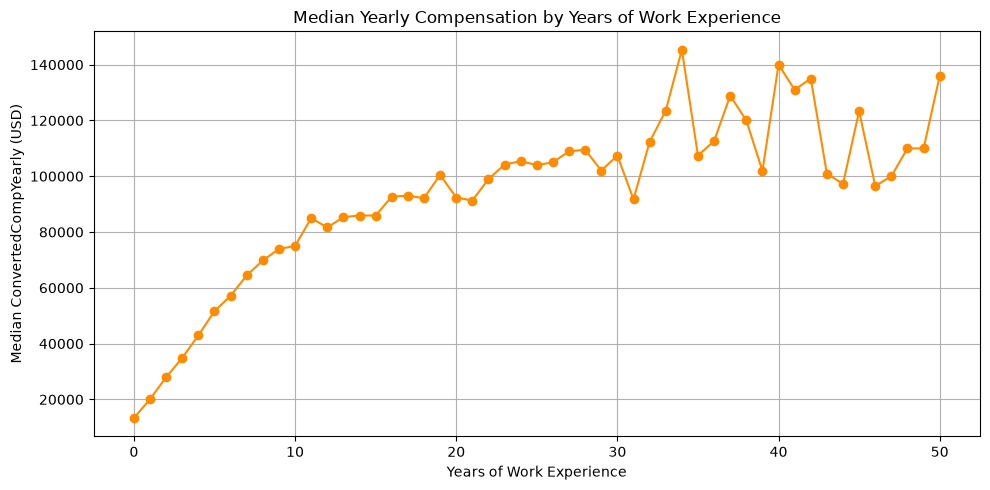

In [16]:
df_comp = df.dropna(subset=['WorkExp', 'ConvertedCompYearly'])

median_comp_exp = df_comp.groupby('WorkExp')['ConvertedCompYearly'].median()

plt.figure(figsize=(10, 5))
plt.plot(median_comp_exp.index, median_comp_exp.values, marker='o', color='darkorange')
plt.title('Median Yearly Compensation by Years of Work Experience')
plt.xlabel('Years of Work Experience')
plt.ylabel('Median ConvertedCompYearly (USD)')
plt.grid(True)
plt.tight_layout()
plt.show()